# Question 3: Which property characteristics are consistently associated with sale price?

This notebook uses a **random forest regressor** (an ensemble of randomized decision trees) to identify property characteristics that consistently predict sale price. It follows the project validation plan: five-fold cross-validation on `train.csv`, with all preprocessing fitted inside each training fold. The unlabeled `test.csv` is not used.

Feature importance is measured by **permutation importance on each held-out fold**: how much the fold's R² decreases when one original feature is shuffled. This gives a comparable importance score per input feature and avoids the split-importance bias of tree impurity scores. Positive importance means the feature helped prediction in that fold; importance indicates predictive association, not causation or effect direction.

## Load data and define property features

To stay consistent with Question 1, remove IDs, location fields, and sale-transaction fields. Preserve the same quality recoding, log transforms, and derived size/age features. `SalePrice` is log-transformed for model fitting, while fold metrics are reported in dollars as well as R².

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder

SEED = 42
DATA_CANDIDATES = [Path("../data/train.csv"), Path("data/train.csv"), Path("train.csv")]
DATA_PATH = next((path for path in DATA_CANDIDATES if path.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError(f"Could not find train.csv in: {DATA_CANDIDATES}")

train = pd.read_csv(DATA_PATH)
price = train["SalePrice"].to_numpy()
y = np.log(price)
print(f"Loaded {train.shape[0]} labeled homes and {train.shape[1]} columns from {DATA_PATH}")

Loaded 1460 labeled homes and 81 columns from ../data/train.csv


In [3]:
QUAL_MAP = {"Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5}
ORDINAL_COLS = [
    "ExterQual", "ExterCond", "BsmtQual", "BsmtCond", "HeatingQC", "KitchenQual",
    "FireplaceQu", "GarageQual", "GarageCond", "PoolQC",
]
LOCATION_COLS = ["Neighborhood", "MSZoning", "Condition1", "Condition2"]
SALE_COLS = ["MoSold", "YrSold", "SaleType", "SaleCondition"]

def build_features(frame):
    features = frame.drop(columns=["Id", "SalePrice"], errors="ignore").copy()
    for column in ORDINAL_COLS:
        features[column] = features[column].map(QUAL_MAP).fillna(0)
    features["TotalSF"] = features["TotalBsmtSF"] + features["1stFlrSF"] + features["2ndFlrSF"]
    features["TotalBath"] = (
        features["FullBath"] + 0.5 * features["HalfBath"]
        + features["BsmtFullBath"] + 0.5 * features["BsmtHalfBath"]
    )
    features["HouseAge"] = features["YrSold"] - features["YearBuilt"]
    features["YearsSinceRemodel"] = features["YrSold"] - features["YearRemodAdd"]
    for column in ["GrLivArea", "LotArea", "TotalSF", "1stFlrSF"]:
        features[column] = np.log1p(features[column])
    features["MSSubClass"] = features["MSSubClass"].astype(str)
    return features.drop(columns=LOCATION_COLS + SALE_COLS)

X = build_features(train)
print(f"Property-only input: {X.shape[1]} original features")
categorical_columns = [column for column in X.columns if pd.api.types.is_string_dtype(X[column].dtype)]
print(f"Numeric: {X.shape[1] - len(categorical_columns)} | Categorical: {len(categorical_columns)}")

Property-only input: 75 original features
Numeric: 47 | Categorical: 28


## Five-fold cross-validation and permutation importance

Numeric missing values are imputed by the training-fold median, and categorical missing values become their own level before one-hot encoding. Permutation importance is computed on the held-out fold using the untransformed feature table, so categories and engineered property variables each get one grouped importance value. A fixed forest configuration is used rather than tuning on the evaluation folds.

In [4]:
def make_forest(features):
    categorical = [column for column in features.columns if pd.api.types.is_string_dtype(features[column].dtype)]
    numeric = [column for column in features.columns if column not in categorical]
    preprocess = ColumnTransformer([
        ("num", SimpleImputer(strategy="median"), numeric),
        ("cat", make_pipeline(
            SimpleImputer(strategy="constant", fill_value="None"),
            OneHotEncoder(handle_unknown="ignore", min_frequency=10),
        ), categorical),
    ])
    forest = RandomForestRegressor(
        n_estimators=300,
        max_features=0.7,
        min_samples_leaf=2,
        random_state=SEED,
        n_jobs=-1,
    )
    return make_pipeline(preprocess, forest)

kf = KFold(n_splits=5, shuffle=True, random_state=SEED)
fold_metrics = []
importance_rows = []
fold_models = []

for fold, (train_idx, valid_idx) in enumerate(kf.split(X), start=1):
    model = make_forest(X)
    model.fit(X.iloc[train_idx], y[train_idx])
    fold_models.append(model)
    valid_prediction = np.exp(model.predict(X.iloc[valid_idx]))
    fold_metrics.append({
        "fold": fold,
        "MAE": mean_absolute_error(price[valid_idx], valid_prediction),
        "RMSE": np.sqrt(mean_squared_error(price[valid_idx], valid_prediction)),
        "R2": r2_score(price[valid_idx], valid_prediction),
    })

    perm = permutation_importance(
        model,
        X.iloc[valid_idx],
        y[valid_idx],
        scoring="r2",
        n_repeats=5,
        random_state=SEED + fold,
        n_jobs=1,
    )
    importance_rows.extend([
        {"fold": fold, "feature": feature, "importance": mean_importance}
        for feature, mean_importance in zip(X.columns, perm.importances_mean)
    ])
    print(f"Completed fold {fold}/5")

fold_results = pd.DataFrame(fold_metrics)
display(fold_results.round(3))
print("Mean ± standard deviation across folds:")
for metric in ["MAE", "RMSE", "R2"]:
    print(f"{metric}: {fold_results[metric].mean():,.3f} ± {fold_results[metric].std():,.3f}")

Completed fold 1/5
Completed fold 2/5
Completed fold 3/5
Completed fold 4/5
Completed fold 5/5


,fold,MAE,RMSE,R2
0,1,16944.596,30450.757,0.879
1,2,16005.638,27362.872,0.890
2,3,19984.173,42836.019,0.668
3,4,17347.255,28128.195,0.874
4,5,14663.614,22440.698,0.904


Mean ± standard deviation across folds:
MAE: 16,989.055 ± 1,966.965
RMSE: 30,243.708 ± 7,620.216
R2: 0.843 ± 0.099


## Which features are consistently useful?

The table ranks original input features by average held-out R² decrease. `Positive folds` counts folds where shuffling hurt prediction, and `Top-10 folds` shows how often a feature ranked among the ten most important. Consistency across folds is more informative than a single fitted forest's ranking. Correlated features can share or mask each other's permutation importance, so a low score does not prove a feature is unrelated.

,mean_importance,sd_across_folds,positive_folds,top10_folds,mean_rank
feature,,,,,
TotalSF,0.2742,0.0342,5,5,1.0
OverallQual,0.1464,0.0433,5,5,2.0
GrLivArea,0.0090,0.0097,4,4,17.4
OverallCond,0.0075,0.0008,5,5,4.8
CentralAir,0.0068,0.0037,5,3,8.4
GarageCars,0.0059,0.0031,5,4,7.2
LotArea,0.0052,0.0023,5,4,8.8
HouseAge,0.0050,0.0025,5,3,9.4
TotalBath,0.0041,0.0011,5,4,9.8


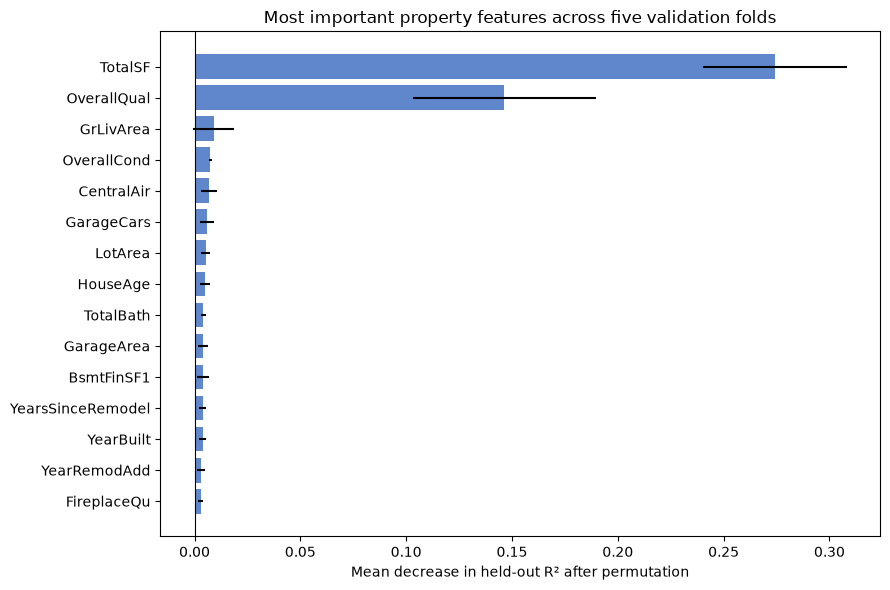

Most consistently useful features (ranked by mean importance):
- TotalSF: positive in 5/5 folds, top 10 in 5/5, mean importance 0.2742 (R² decrease).
- OverallQual: positive in 5/5 folds, top 10 in 5/5, mean importance 0.1464 (R² decrease).
- GrLivArea: positive in 4/5 folds, top 10 in 4/5, mean importance 0.0090 (R² decrease).
- OverallCond: positive in 5/5 folds, top 10 in 5/5, mean importance 0.0075 (R² decrease).
- CentralAir: positive in 5/5 folds, top 10 in 3/5, mean importance 0.0068 (R² decrease).
- GarageCars: positive in 5/5 folds, top 10 in 4/5, mean importance 0.0059 (R² decrease).
- LotArea: positive in 5/5 folds, top 10 in 4/5, mean importance 0.0052 (R² decrease).
- HouseAge: positive in 5/5 folds, top 10 in 3/5, mean importance 0.0050 (R² decrease).


In [5]:
importance = pd.DataFrame(importance_rows)
importance["fold_rank"] = importance.groupby("fold")["importance"].rank(ascending=False, method="min")
importance_summary = (
    importance.groupby("feature")
    .agg(
        mean_importance=("importance", "mean"),
        sd_across_folds=("importance", "std"),
        positive_folds=("importance", lambda values: int((values > 0).sum())),
        top10_folds=("fold_rank", lambda ranks: int((ranks <= 10).sum())),
        mean_rank=("fold_rank", "mean"),
    )
    .sort_values("mean_importance", ascending=False)
)
display(importance_summary.head(15).round(4))

top = importance_summary.head(15).sort_values("mean_importance")
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top.index, top["mean_importance"], xerr=top["sd_across_folds"], color="#4472C4", alpha=0.85)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Mean decrease in held-out R² after permutation")
ax.set_title("Most important property features across five validation folds")
plt.tight_layout()
plt.show()

print("Most consistently useful features (ranked by mean importance):")
for feature, row in importance_summary.head(8).iterrows():
    print(
        f"- {feature}: positive in {int(row['positive_folds'])}/5 folds, "
        f"top 10 in {int(row['top10_folds'])}/5, "
        f"mean importance {row['mean_importance']:.4f} (R² decrease)."
    )

## Do combinations of features add useful information?

The forest can learn interactions automatically. To look for useful combinations, we examine three plausible pairs among the consistently important features: **total floor area × overall quality**, **total floor area × garage capacity**, and **house age × overall quality**. First, we jointly shuffle each pair in each held-out fold; the joint R² drop measures how much predictive information the pair carries together (joint shuffling preserves the relationship between the two features). We compare this with shuffling either feature alone. Second, two-way partial-dependence surfaces show how the forest's average predicted log-price changes over each pair, and a Friedman-style H score summarizes non-additivity of that surface. These are exploratory analyses, not causal effects or proof that adding a handcrafted interaction improves the model.

Completed pair analysis for fold 1/5


Completed pair analysis for fold 2/5


Completed pair analysis for fold 3/5


Completed pair analysis for fold 4/5


Completed pair analysis for fold 5/5


,joint_r2_drop_mean,joint_r2_drop_sd,joint_positive_folds,extra_over_best_single_mean,extra_positive_folds
pair,,,,,
TotalSF × OverallQual,0.7055,0.0442,5,0.4309,5
TotalSF × GarageCars,0.3034,0.0322,5,0.0264,5
HouseAge × OverallQual,0.1686,0.0263,5,0.0207,5


,mean,std,folds
pair,,,
TotalSF × OverallQual,0.253,0.013,5
TotalSF × GarageCars,0.028,0.015,5
HouseAge × OverallQual,0.022,0.005,5


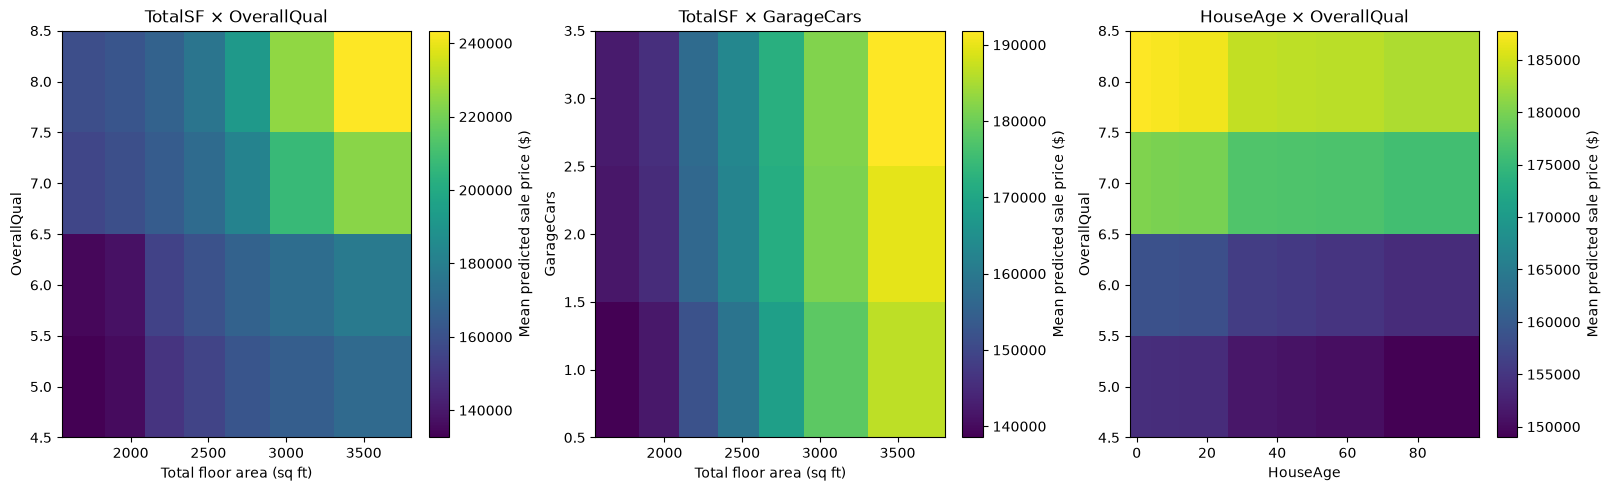

In [5]:
PAIR_CANDIDATES = [
    ("TotalSF", "OverallQual"),
    ("TotalSF", "GarageCars"),
    ("HouseAge", "OverallQual"),
]

pair_importance_rows = []
interaction_rows = []
interaction_surfaces = {pair: [] for pair in PAIR_CANDIDATES}
grid_quantiles = np.linspace(0.1, 0.9, 7)
feature_grids = {
    feature: np.unique(np.quantile(X[feature], grid_quantiles))
    for pair in PAIR_CANDIDATES for feature in pair
}

for fold, (train_idx, valid_idx) in enumerate(kf.split(X), start=1):
    model = fold_models[fold - 1]
    valid = X.iloc[valid_idx]
    actual_log_price = y[valid_idx]
    baseline_r2 = r2_score(actual_log_price, model.predict(valid))

    for pair_number, (feature_a, feature_b) in enumerate(PAIR_CANDIDATES, start=1):
        pair_name = f"{feature_a} × {feature_b}"
        for repeat in range(10):
            permutation = np.random.default_rng(SEED + fold * 100 + pair_number * 10 + repeat).permutation(len(valid))
            for variable, columns in [
                ("single_a", [feature_a]),
                ("single_b", [feature_b]),
                ("joint", [feature_a, feature_b]),
            ]:
                shuffled = valid.copy()
                for column in columns:
                    shuffled[column] = valid[column].to_numpy()[permutation]
                drop = r2_score(actual_log_price, model.predict(shuffled))
                pair_importance_rows.append({
                    "fold": fold,
                    "pair": pair_name,
                    "variable": variable,
                    "r2_drop": baseline_r2 - drop,
                })

    for pair in PAIR_CANDIDATES:
        feature_a, feature_b = pair
        grid_a = feature_grids[feature_a]
        grid_b = feature_grids[feature_b]
        reference = valid.sample(n=min(150, len(valid)), random_state=SEED + fold)
        surface = np.empty((len(grid_a), len(grid_b)))
        for i, value_a in enumerate(grid_a):
            for j, value_b in enumerate(grid_b):
                modified = reference.copy()
                modified[feature_a] = value_a
                modified[feature_b] = value_b
                surface[i, j] = model.predict(modified).mean()

        grand_mean = surface.mean()
        main_a = surface.mean(axis=1)[:, None] - grand_mean
        main_b = surface.mean(axis=0)[None, :] - grand_mean
        interaction_residual = surface - grand_mean - main_a - main_b
        total_variation = np.sum((surface - grand_mean) ** 2)
        h_score = np.sqrt(np.sum(interaction_residual ** 2) / total_variation) if total_variation > 0 else 0.0
        interaction_rows.append({"fold": fold, "pair": f"{feature_a} × {feature_b}", "H_score": h_score})
        interaction_surfaces[pair].append((grid_a, grid_b, surface))

    print(f"Completed pair analysis for fold {fold}/5")

pair_fold_importance = (
    pd.DataFrame(pair_importance_rows)
    .groupby(["pair", "fold", "variable"])["r2_drop"]
    .mean()
    .unstack("variable")
)
pair_fold_importance["extra_vs_best_single"] = (
    pair_fold_importance["joint"]
    - pair_fold_importance[["single_a", "single_b"]].max(axis=1)
)
pair_summary = pair_fold_importance.groupby("pair").agg(
    joint_r2_drop_mean=("joint", "mean"),
    joint_r2_drop_sd=("joint", "std"),
    joint_positive_folds=("joint", lambda values: int((values > 0).sum())),
    extra_over_best_single_mean=("extra_vs_best_single", "mean"),
    extra_positive_folds=("extra_vs_best_single", lambda values: int((values > 0).sum())),
)
display(pair_summary.sort_values("joint_r2_drop_mean", ascending=False).round(4))

interaction_summary = pd.DataFrame(interaction_rows).groupby("pair")["H_score"].agg(["mean", "std"])
interaction_summary["folds"] = 5
display(interaction_summary.sort_values("mean", ascending=False).round(3))

fig, axes = plt.subplots(1, len(PAIR_CANDIDATES), figsize=(16, 4.8), constrained_layout=True)
for ax, pair in zip(axes, PAIR_CANDIDATES):
    fold_data = interaction_surfaces[pair]
    grid_a, grid_b = fold_data[0][:2]
    mean_surface = np.mean([surface for _, _, surface in fold_data], axis=0)
    x_values = np.expm1(grid_a) if pair[0] == "TotalSF" else grid_a
    y_values = np.expm1(grid_b) if pair[1] == "TotalSF" else grid_b
    x_edges = np.r_[x_values[0] - (x_values[1] - x_values[0]) / 2,
                    (x_values[:-1] + x_values[1:]) / 2,
                    x_values[-1] + (x_values[-1] - x_values[-2]) / 2]
    y_edges = np.r_[y_values[0] - (y_values[1] - y_values[0]) / 2,
                    (y_values[:-1] + y_values[1:]) / 2,
                    y_values[-1] + (y_values[-1] - y_values[-2]) / 2]
    image = ax.pcolormesh(x_edges, y_edges, np.exp(mean_surface).T, shading="flat", cmap="viridis")
    ax.set_xlabel("Total floor area (sq ft)" if pair[0] == "TotalSF" else pair[0])
    ax.set_ylabel("Total floor area (sq ft)" if pair[1] == "TotalSF" else pair[1])
    ax.set_title(f"{pair[0]} × {pair[1]}")
    fig.colorbar(image, ax=ax, label="Mean predicted sale price ($)")
plt.show()

## Interpretation and limitations

**Main-effect finding:** `TotalSF` (basement plus first- and second-floor area) and `OverallQual` were the strongest and most stable individual predictors: both had positive permutation importance and ranked in the top 10 in all five folds (mean held-out R² decrease 0.274 and 0.146, respectively). `OverallCond` was also positive and top-10 in all five folds; `GarageCars`, `LotArea`, and `HouseAge` were positive in all five and top-10 in three to four folds. The forest's five-fold metrics were MAE = 16,989 ± 1,967 dollars, RMSE = 30,244 ± 7,620 dollars, and R² = 0.843 ± 0.099.

**Combination finding:** `TotalSF × OverallQual` stands out. Jointly permuting this pair reduced held-out R² by 0.706 on average (SD 0.044), and the pair's drop exceeded the stronger single feature's drop by 0.431 in every fold. Its two-way partial-dependence H score was 0.253 ± 0.013, notably higher than `TotalSF × GarageCars` (0.028 ± 0.015) and `HouseAge × OverallQual` (0.022 ± 0.005), suggesting the area-quality surface has the clearest non-additive pattern of the pairs examined. The other pairs had much smaller incremental joint information over their stronger individual feature (0.026 and 0.021 R², respectively).

These are predictive associations within this Ames Housing sample, not causal renovation effects. Joint permutation importance measures how much the fitted model relies on the pair's combined information; it is not a measured improvement from adding a new interaction term, and its difference from a single feature is not a pure interaction effect. The H score summarizes non-additivity of a marginal partial-dependence surface; correlated inputs can make some combinations unrealistic. The candidate pairs were chosen for an exploratory follow-up, so treat the rankings as hypotheses to investigate rather than independently confirmed effects.


Permutation importance does not show whether larger or better values raise or lower price. Correlated features may dilute one another's measured importance, and the random forest settings were fixed rather than tuned. The provided `test.csv` has no `SalePrice`, so the cross-validation results are the available estimate of performance; no test score is reported.